In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from pathlib import Path

from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import lightgbm as lg

from statsmodels.tsa.api import SimpleExpSmoothing, Holt, ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams['figure.dpi'] = 100
RNG = 42
np.random.seed(RNG)

TARGETS = {
    'Avg Temp': 'Average Annual Temperature (F)',
    'ToT Prcp': 'Total Annual Precipitation (in)',
    'Max Tmax': 'Hottest Day of the Year (F)',
    'cdd': 'Cooling Degree Days (F-days)',
}
TCOLS = list(TARGETS)
HORIZON = 7
FIRST_FORECAST_YEAR = 2019

In [2]:
# !pip uninstall -y brotli
# !pip install --upgrade brotlicffi

In [3]:
from datasets import load_dataset

REPO = "CMU-OSPO/protostar-climate-train-to-2018"
CACHE = Path('/tmp/annual.parquet')
if CACHE.exists():
  annual = pd.read_parquet(CACHE)
else:
  annual = load_dataset(REPO, "annual_indices", split="train").to_pandas()
cities = load_dataset(REPO, "city_info", split="train").to_pandas()
print(annual.shape, annual['Name'].nunique(), 'cities;', annual['Year'].min(), '-', annual['Year'].max())


(28052, 24) 210 cities; 1851 - 2018


### Data Audit and Cleaning

In [4]:
MISS_TOL = 60 # days; a year with >60 missing days (~16%) is not trusted

df = annual.copy()
df = df.replace([np.inf, -np.inf], np.nan)

bad_t = (df['Miss Tmax'] > MISS_TOL) | (df['Miss Tmin'] > MISS_TOL)
bad_p = df['Miss Prcp'] > MISS_TOL

audit = pd.DataFrame({
    'raw_nan': df[TCOLS].isna().sum(),
    'flagged_by_missing_days': pd.Series({
        'Avg Temp': int(bad_t.sum()), 'Max Tmax': int(bad_t.sum()),
        'cdd': int(bad_t.sum()), 'ToT Prcp': int(bad_p.sum())}),
    })
display(audit)

for c in ['Avg Temp', 'Max Tmax', 'cdd']:
  df.loc[bad_t, c] = np.nan
df.loc[bad_p, 'ToT Prcp'] = np.nan

df = df.sort_values(['Name', 'Year']).reset_index(drop=True)
print('NaN after cleaning:'); display(df[TCOLS].isna().sum().to_frame('nan_count'))
print('Rows with all four targets valid:', int(df[TCOLS].notna().all(axis=1).sum()), 'of', len(df))

,raw_nan,flagged_by_missing_days
Avg Temp,1193,1902
Max Tmax,1184,1902
ToT Prcp,0,1858
cdd,1206,1902


NaN after cleaning:


,nan_count
Avg Temp,1902
ToT Prcp,1858
Max Tmax,1902
cdd,1902


Rows with all four targets valid: 25714 of 28052


In [5]:
# The last 30 years (the training window the baselines use) must be well-populated.
recent = df[df['Year'].between(1989, 2018)]
cov = recent.groupby('Name')[TCOLS].apply(lambda g: g.notna().mean()).min(axis=1)
print('Worst per-city coverage of valid values, 1989-2018:', round(cov.min(), 3))
print('Cities with < 80% coverage:', (cov < 0.8).sum())
print('Valid target rows in 2018:', df[df.Year == 2018][TCOLS].notna().sum().to_dict())

Worst per-city coverage of valid values, 1989-2018: 0.033
Cities with < 80% coverage: 9
Valid target rows in 2018: {'Avg Temp': 210, 'ToT Prcp': 209, 'Max Tmax': 210, 'cdd': 210}


### EDA

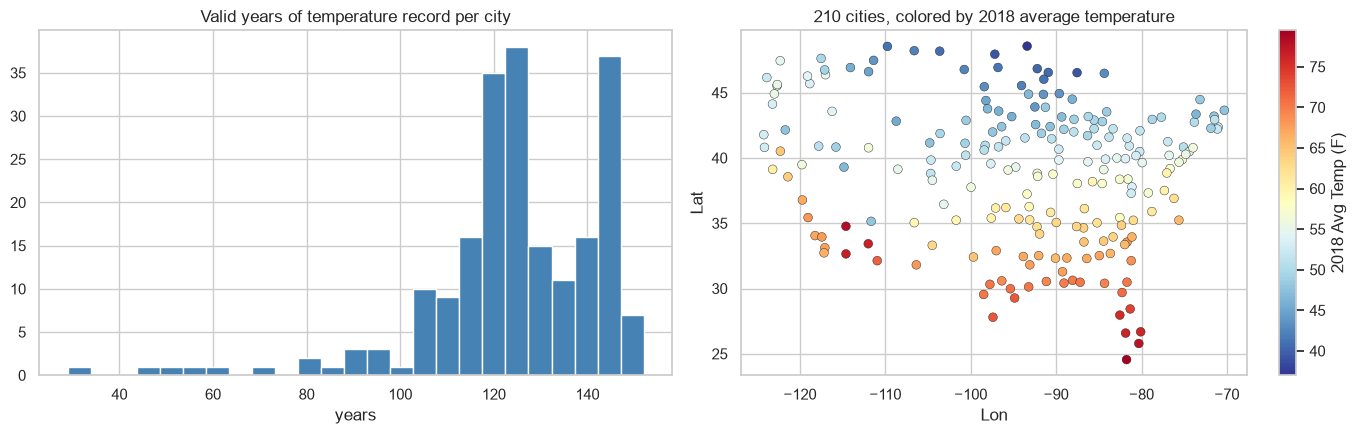

In [6]:
# how long is each city's record and where are the cities?
span = df.dropna(subset=['Avg Temp']).groupby('Name')['Year'].agg(['min', 'max', 'count'])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].hist(span['count'], bins=25, color='steelblue')
ax[0].set_title('Valid years of temperature record per city')
ax[0].set_xlabel('years')
last = df[df.Year == 2018].dropna(subset=['Avg Temp'])
sc = ax[1].scatter(last['Lon'], last['Lat'], c=last['Avg Temp'], cmap='RdYlBu_r', s=40, edgecolor='k', linewidth=0.3)
plt.colorbar(sc, ax=ax[1], label='2018 Avg Temp (F)')
ax[1].set_title('210 cities, colored by 2018 average temperature')
ax[1].set_xlabel('Lon'); ax[1].set_ylabel('Lat')
plt.tight_layout(); plt.show()

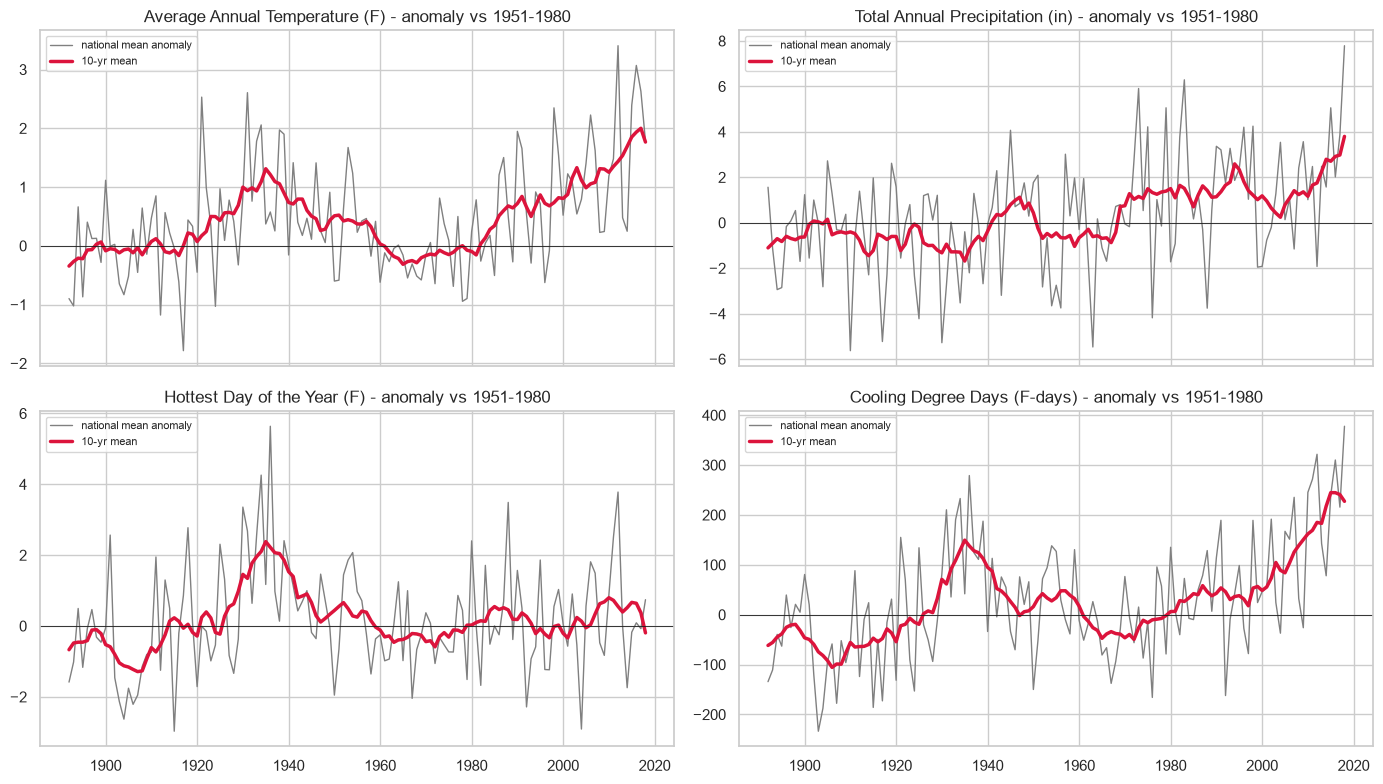

In [7]:
# 2.2 National-average time series (mean of city anomalies, so station mix does not bias it)
def anomaly_by_city(frame, col, base=(1951, 1980)):
    b = frame[frame.Year.between(*base)].groupby('Name')[col].mean()
    return frame[col] - frame['Name'].map(b)

fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=True)
for ax, (c, lab) in zip(axes.ravel(), TARGETS.items()):
    tmp = df[['Name', 'Year', c]].copy()
    tmp['anom'] = anomaly_by_city(df, c)
    nat = tmp.groupby('Year')['anom'].agg(['mean', 'count'])
    nat = nat[nat['count'] >= 100]
    ax.plot(nat.index, nat['mean'], color='grey', lw=1, label='national mean anomaly')
    ax.plot(nat.index, nat['mean'].rolling(10, center=True, min_periods=5).mean(), color='crimson', lw=2.5, label='10-yr mean')
    ax.axhline(0, color='k', lw=0.6); ax.set_title(lab + ' - anomaly vs 1951-1980')
    ax.legend(loc='upper left', fontsize=8)
plt.tight_layout(); plt.show()

,mean,std,min,50%,max
Avg Temp,0.521,0.327,-0.675,0.542,1.625
ToT Prcp,0.492,1.645,-6.862,0.406,5.262
Max Tmax,0.299,0.659,-1.742,0.316,2.198
cdd,92.576,59.312,-52.838,89.854,296.203


Share of cities with positive 1989-2018 trend:


,share_positive
Avg Temp,0.93
ToT Prcp,0.60
Max Tmax,0.68
cdd,0.94


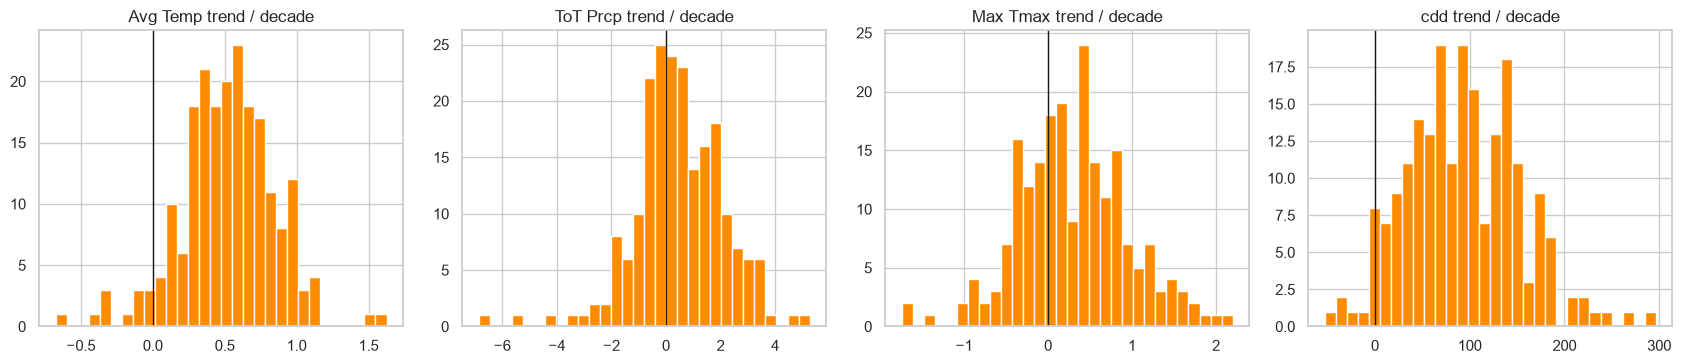

In [8]:
# 2.3 Is the warming real and heterogeneous? Per-city OLS slope over the last 30 years (1989-2018), per decade
def slope_per_decade(g, col):
    g = g.dropna(subset=[col])
    if len(g) < 20:
        return np.nan
    return np.polyfit(g['Year'], g[col], 1)[0] * 10

rec = df[df.Year.between(1989, 2018)]
slopes = pd.DataFrame({c: rec.groupby('Name').apply(lambda g, c=c: slope_per_decade(g, c)) for c in TCOLS})
display(slopes.describe().T[['mean', 'std', 'min', '50%', 'max']].round(3))
print('Share of cities with positive 1989-2018 trend:'); display((slopes > 0).mean().round(2).to_frame('share_positive'))

fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, (c, lab) in zip(axes, TARGETS.items()):
    ax.hist(slopes[c].dropna(), bins=30, color='darkorange', edgecolor='white')
    ax.axvline(0, color='k', lw=1); ax.set_title(c + ' trend / decade')
plt.tight_layout(); plt.show()

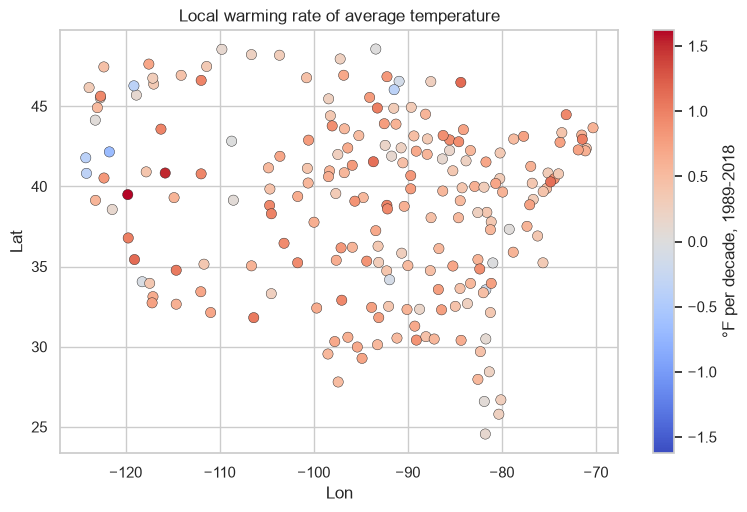

In [9]:
# 2.4 Where is the trend strongest? Map of per-city temperature trend
m = slopes[['Avg Temp']].join(df.groupby('Name')[['Lat', 'Lon']].first())
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(m['Lon'], m['Lat'], c=m['Avg Temp'], cmap='coolwarm', s=55, edgecolor='k', linewidth=0.3,
                vmin=-m['Avg Temp'].abs().max(), vmax=m['Avg Temp'].abs().max())
plt.colorbar(sc, label='°F per decade, 1989-2018')
ax.set_title('Local warming rate of average temperature'); ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
plt.show()

In [10]:
# 2.5 Noise floor: year-to-year variability around each city's own smooth trend.
# A forecast cannot beat this irreducible interannual noise on average, so it frames "good" MAE.
def detrended_abs_dev(g, col, win=30):
    g = g[g.Year >= 1989].dropna(subset=[col])
    if len(g) < 20:
        return np.nan
    p = np.polyfit(g['Year'], g[col], 1)
    return np.mean(np.abs(g[col] - np.polyval(p, g['Year'])))

floor = pd.DataFrame({c: df.groupby('Name').apply(lambda g, c=c: detrended_abs_dev(g, c)) for c in TCOLS})
print('Mean absolute deviation around each city\'s own 1989-2018 linear trend (an in-sample noise floor):')
display(floor.mean().round(3).to_frame('noise_floor_MAE'))

Mean absolute deviation around each city's own 1989-2018 linear trend (an in-sample noise floor):


,noise_floor_MAE
Avg Temp,1.049
ToT Prcp,5.479
Max Tmax,2.385
cdd,143.840


In [11]:
# 2.6 Persistence: lag-1 autocorrelation of city anomalies (after removing each city's mean).
# High value => last year is informative; low => it is mostly noise.
ac = {}
for c in TCOLS:
    w = df[df.Year >= 1950].pivot(index='Year', columns='Name', values=c)
    w = w - w.mean()
    ac[c] = {f'lag{k}': np.nanmean([w[col].autocorr(k) for col in w.columns]) for k in (1, 2, 3, 5)}
display(pd.DataFrame(ac).T.round(3))

,lag1,lag2,lag3,lag5
Avg Temp,0.412,0.162,0.169,0.225
ToT Prcp,0.072,0.059,0.020,0.014
Max Tmax,0.137,0.071,-0.009,0.020
cdd,0.244,0.166,0.140,0.191


In [12]:
# 2.7 Cross-city structure: do all cities move together in a given year (shared signal)?
# Share of variance of year-to-year anomalies explained by the national common component.
rows = []
for c in TCOLS:
    w = df[df.Year >= 1950].pivot(index='Year', columns='Name', values=c)
    a = w - w.mean()
    nat = a.mean(axis=1)
    r2 = np.nanmean([np.corrcoef(a[col].dropna(), nat.loc[a[col].dropna().index])[0, 1] ** 2 for col in a.columns if a[col].notna().sum() > 30])
    rows.append((c, r2))
display(pd.DataFrame(rows, columns=['metric', 'mean R2 with national mean']).set_index('metric').round(3))

,mean R2 with national mean
metric,
Avg Temp,0.488
ToT Prcp,0.147
Max Tmax,0.235
cdd,0.381


## 3. Backtest design and the three required baselines

* We cannot score 2019-2025 yet, so we **replay the challenge in the past** (rolling-origin backtest):
* Pick an origin year 'T' (as if it were "end of 2018"). Use only data with 'Year <= T'.
* Forecast years 'T+1 ... T+7' for every city (horizons h = 1..7).
* Score against the actual values. Repeat for origins T = 1995 ... 2011 (so 'T+7 <= 2018').
* Pool MAE across cities, horizons and origins. Only valid (non-NaN) actuals are scored.

**Baselines** (exactly as the challenge defines them):
1. **Last Year Repeated** - the value at year 'T' repeated for all 7 years (if 'T' is missing, the most recent valid year).
2. **30-Year Average** - per-city mean of the last 30 years up to 'T'.
3. **Linear Trend** - per-city straight line fitted to the last 30 years up to 'T', extrapolated.

In [13]:
# Wide matrices: rows = years, columns = cities
YEARS = np.arange(df.Year.min(), 2019)
CITIES = sorted(df.Name.unique())
W = {c: df.pivot(index='Year', columns='Name', values=c).reindex(index=YEARS, columns=CITIES) for c in TCOLS}
META = df.groupby('Name')[['Lat', 'Lon']].first().reindex(CITIES)

def last_valid(M, T):
    """Most recent non-NaN value at or before year T, per city."""
    return M.loc[:T].ffill().iloc[-1]

def baseline_last_year(M, T):
    return last_valid(M, T)

def baseline_avg30(M, T):
    return M.loc[T - 29:T].mean()

def baseline_trend30(M, T, min_pts=15):
    sub = M.loc[T - 29:T]
    x = sub.index.values.astype(float)
    out = {}
    for city in sub.columns:
        y = sub[city].values
        ok = ~np.isnan(y)
        if ok.sum() >= min_pts:
            out[city] = np.polyfit(x[ok], y[ok], 1)
        else:
            out[city] = (0.0, np.nan)
    return pd.Series(out)  # (slope, intercept) per city

def trend30_forecast(M, T, h, coefs=None):
    coefs = baseline_trend30(M, T) if coefs is None else coefs
    return pd.Series({c: coefs[c][0] * (T + h) + coefs[c][1] for c in M.columns})

# sanity check on the real 2018 origin for one city
for c in TCOLS:
    print(c, '| Aberdeen 2018 last-yr=%.1f avg30=%.1f trend30(2019)=%.1f' % (
        baseline_last_year(W[c], 2018)['Aberdeen'], baseline_avg30(W[c], 2018)['Aberdeen'],
        trend30_forecast(W[c], 2018, 1)['Aberdeen']))

Avg Temp | Aberdeen 2018 last-yr=43.2 avg30=43.7 trend30(2019)=44.1
ToT Prcp | Aberdeen 2018 last-yr=17.9 avg30=21.7 trend30(2019)=19.9
Max Tmax | Aberdeen 2018 last-yr=100.9 avg30=98.1 trend30(2019)=99.0
cdd | Aberdeen 2018 last-yr=820.9 avg30=579.7 trend30(2019)=618.0


In [14]:
ORIGINS = list(range(1995, 2012))  # T+7 <= 2018

def run_baselines(origins=ORIGINS):
    recs = []
    for c in TCOLS:
        M = W[c]
        for T in origins:
            ly, a30 = baseline_last_year(M, T), baseline_avg30(M, T)
            coefs = baseline_trend30(M, T)
            for h in range(1, HORIZON + 1):
                y = M.loc[T + h]
                tr = trend30_forecast(M, T, h, coefs)
                recs.append(pd.DataFrame({
                    'target': c, 'origin': T, 'h': h, 'city': CITIES, 'y': y.values,
                    'Last Year': ly.values, '30-Yr Avg': a30.values, 'Linear Trend': tr.values}))
    return pd.concat(recs, ignore_index=True)

In [15]:
ORIGINS = list(range(1995, 2012))  # T+7 <= 2018

def run_baselines(origins=ORIGINS):
    recs = []
    for c in TCOLS:
        M = W[c]
        for T in origins:
            ly, a30 = baseline_last_year(M, T), baseline_avg30(M, T)
            coefs = baseline_trend30(M, T)
            for h in range(1, HORIZON + 1):
                y = M.loc[T + h]
                tr = trend30_forecast(M, T, h, coefs)
                recs.append(pd.DataFrame({
                    'target': c, 'origin': T, 'h': h, 'city': CITIES, 'y': y.values,
                    'Last Year': ly.values, '30-Yr Avg': a30.values, 'Linear Trend': tr.values}))
    return pd.concat(recs, ignore_index=True)

bt = run_baselines()
print(bt.shape)
BASE = ['Last Year', '30-Yr Avg', 'Linear Trend']

def mae_table(frame, methods, by=None):
    f = frame.dropna(subset=['y'] + methods)  # score only rows where every method produced a forecast
    g = f.groupby(by) if by else f.assign(_all=1).groupby('_all')
    return g.apply(lambda d: pd.Series({m: np.mean(np.abs(d[m] - d['y'])) for m in methods}))

res_base = mae_table(bt, BASE, by='target').loc[TCOLS]
display(res_base.round(3))

(99960, 8)


,Last Year,30-Yr Avg,Linear Trend
target,,,
Avg Temp,1.443,1.303,1.173
ToT Prcp,7.895,5.829,6.183
Max Tmax,3.538,2.625,2.824
cdd,209.866,180.578,170.747


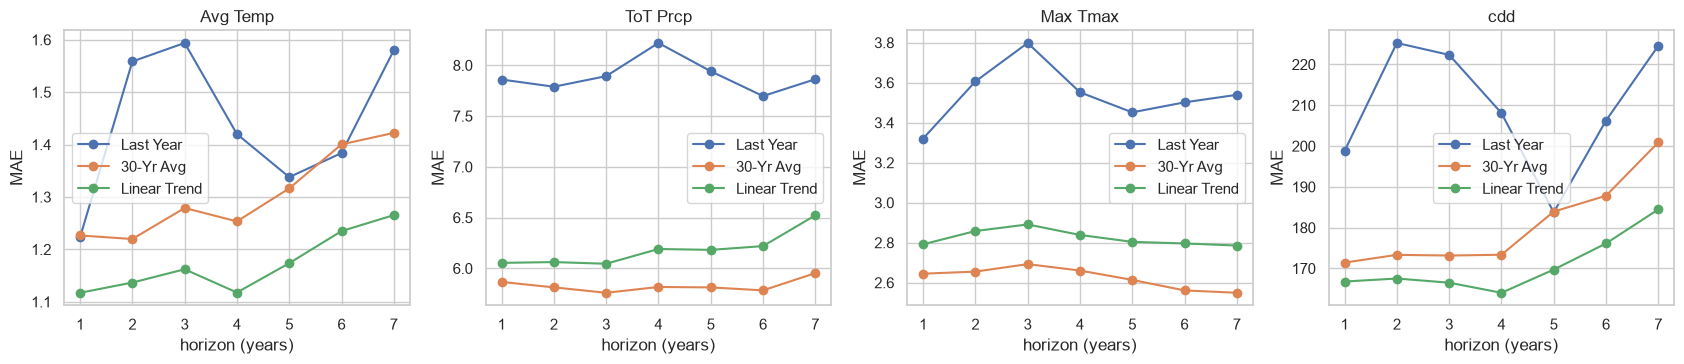

In [16]:
# MAE by forecast horizon: does the ranking of baselines change with lead time?
by_h = mae_table(bt, BASE, by=['target', 'h'])
fig, axes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, c in zip(axes, TCOLS):
    by_h.loc[c].plot(ax=ax, marker='o')
    ax.set_title(c); ax.set_xlabel('horizon (years)'); ax.set_ylabel('MAE')
plt.tight_layout(); plt.show()

## 4. Models

* **Global direct multi-horizon models** trained across all cities at once (more data, shared climate physics), one model per target:
*
* Row = (city, origin year 'T', horizon 'h' = 1..7). Target = 'y(T+h) - avg30(T)' (anomaly vs the city's own 30-year climatology).
* Features, all computed from data up to 'T' only: last valid value, 5/10/30-year means (as anomalies vs avg30), the 30-year linear-trend offset
* **No leakage:** when forecasting from origin 'T', training rows are limited to those with `origin + h <= T`.
*
* Models compared: **Ridge**, **LightGBM** (L1 objective, since MAE is the metric), **Half-Trend** (a damped trend halfway between the 30-yr average

In [17]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

FEATS = ['ly_a', 'a5_a', 'a10_a', 'trend_off', 'slope', 'sd30', 'lat', 'lon', 'h', 'a30', 'nat_ly', 'nat_a5']
ALL_YEARS = np.arange(YEARS.min(), 2019 + HORIZON)

def build_panels(c, first_origin=1925):
    M = W[c].reindex(ALL_YEARS)
    recs = []
    for T in range(first_origin, 2019):
        a30, a10, a5 = M.loc[T - 29:T].mean(), M.loc[T - 9:T].mean(), M.loc[T - 4:T].mean()
        ly = last_valid(M.loc[:2018], T)
        sd = M.loc[T - 29:T].std()
        coefs = baseline_trend30(M.loc[:2018], T)
        slope = pd.Series({k: v[0] for k, v in coefs.items()})
        nat_ly, nat_a5 = (ly - a30).mean(), (a5 - a30).mean()
        for h in range(1, HORIZON + 1):
            tr = trend30_forecast(M.loc[:2018], T, h, coefs)
            # ... truncated at the bottom of the screen

In [18]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

FEATS = ['ly_a', 'a5_a', 'a10_a', 'trend_off', 'slope', 'sd30', 'lat', 'lon', 'h', 'a30', 'nat_ly', 'nat_a5']
ALL_YEARS = np.arange(YEARS.min(), 2019 + HORIZON)

def build_panel(c, first_origin=1925):
    M = W[c].reindex(ALL_YEARS)
    recs = []
    for T in range(first_origin, 2019):
        a30, a10, a5 = M.loc[T - 29:T].mean(), M.loc[T - 9:T].mean(), M.loc[T - 4:T].mean()
        ly = last_valid(M.loc[:2018], T)
        sd = M.loc[T - 29:T].std()
        coefs = baseline_trend30(M.loc[:2018], T)
        slope = pd.Series({k: v[0] for k, v in coefs.items()})
        nat_ly, nat_a5 = (ly - a30).mean(), (a5 - a30).mean()
        for h in range(1, HORIZON + 1):
            tr = trend30_forecast(M.loc[:2018], T, h, coefs)
            recs.append(pd.DataFrame({
                'city': CITIES, 'origin': T, 'h': h, 'y': M.loc[T + h].values,
                'a30': a30.values, 'ly_a': (ly - a30).values, 'a5_a': (a5 - a30).values, 'a10_a': (a10 - a30).values,
                'trend_off': (tr - a30).values, 'slope': slope.values, 'sd30': sd.values,
                'lat': META['Lat'].values, 'lon': META['Lon'].values, 'nat_ly': nat_ly, 'nat_a5': nat_a5,
                'Last Year': ly.values, 'Linear Trend': tr.values, '30-Yr Avg': a30.values}))
    p = pd.concat(recs, ignore_index=True)
    p['target_year'] = p['origin'] + p['h']
    return p

PANEL = {c: build_panel(c) for c in TCOLS}
print({c: p.shape for c, p in PANEL.items()})

{'Avg Temp': (138180, 19), 'ToT Prcp': (138180, 19), 'Max Tmax': (138180, 19), 'cdd': (138180, 19)}


In [19]:
LGB_PARAMS = dict(objective='l1', n_estimators=300, learning_rate=0.03, num_leaves=15, min_child_samples=100,
                 subsample=0.8, subsample_freq=1, colsample_bytree=0.8, reg_lambda=1.0, random_state=RNG, verbose=-1, n_jobs=8)

def fit_predict(c, T, return_models=False):
    p = PANEL[c]
    train = p[(p.target_year <= T) & p['y'].notna() & p['a30'].notna() & (p.origin >= 1925)]
    test = p[p.origin == T].copy()
    ytr = (train['y'] - train['a30']).values
    ridge = make_pipeline(SimpleImputer(strategy='median'), StandardScaler(), Ridge(alpha=10.0)).fit(train[FEATS], ytr)
    gbm = lg.LGBMRegressor(**LGB_PARAMS).fit(train[FEATS], ytr)
    test['Ridge'] = test['a30'] + ridge.predict(test[FEATS])
    test['LightGBM'] = test['a30'] + gbm.predict(test[FEATS])
    test['Half-Trend'] = 0.5 * (test['30-Yr Avg'] + test['Linear Trend'])
    test['Ensemble'] = (test['LightGBM'] + test['Ridge'] + test['Linear Trend']) / 3
    test['target'] = c
    out = test[['target', 'origin', 'h', 'city', 'y', 'Last Year', '30-Yr Avg', 'Linear Trend', 'Half-Trend', 'Ridge', 'LightGBM', 'Ensemble']]
    return (out, gbm) if return_models else out

In [20]:
from tqdm.auto import tqdm
bt_all = pd.concat([fit_predict(c, T) for c in TCOLS for T in tqdm(ORIGINS, desc=c)], ignore_index=True)
METHODS = ['Last Year', '30-Yr Avg', 'Linear Trend', 'Half-Trend', 'Ridge', 'LightGBM', 'Ensemble']
print(bt_all.shape)

cdd: 100%|██████████| 17/17 [00:10<00:00,  1.67it/s]

(99960, 12)


In [21]:
# !pip install jinja2
import sys
import jinja2

print(sys.executable)
print(jinja2.__version__)

c:\DataScience\Anaconda\envs\dev\python.exe
3.1.5


In [23]:
# ## 5. Evaluation
#
# Pooled MAE over 17 origins * 7 horizons * ~210 cities, one row per metric. Lower is better. "Skill" = relative MAE reduction vs the best of the three required baselines.

res = mae_table(bt_all, METHODS, by='target').loc[TCOLS]
print('Pooled MAE by target (lower is better):')
display(res.round(3))

best_base = res[BASE].min(axis=1)
skill = (1 - res[METHODS].div(best_base, axis=0)) * 100
print('Skill vs best baseline (%, positive = better):')
display(skill.round(1))

Pooled MAE by target (lower is better):


,Last Year,30-Yr Avg,Linear Trend,Half-Trend,Ridge,LightGBM,Ensemble
target,,,,,,,
Avg Temp,1.443,1.303,1.173,1.159,1.178,1.211,1.149
ToT Prcp,7.895,5.829,6.183,5.882,5.848,5.814,5.848
Max Tmax,3.538,2.625,2.824,2.650,2.648,2.678,2.670
cdd,209.866,180.578,170.747,168.341,165.588,165.953,163.746


Skill vs best baseline (%, positive = better):


,Last Year,30-Yr Avg,Linear Trend,Half-Trend,Ridge,LightGBM,Ensemble
target,,,,,,,
Avg Temp,-23.0,-11.1,0.0,1.1,-0.4,-3.3,2.0
ToT Prcp,-35.4,0.0,-6.1,-0.9,-0.3,0.3,-0.3
Max Tmax,-34.8,0.0,-7.5,-0.9,-0.9,-2.0,-1.7
cdd,-22.9,-5.8,0.0,1.4,3.0,2.8,4.1


In [24]:
# Paired uncertainty: bootstrap over (origin) blocks, because errors within an origin year are strongly correlated.
def block_bootstrap_diff(frame, m_new, m_ref, n=500, seed=RNG):
    f = frame.dropna(subset=['y', m_new, m_ref])
    per = f.groupby('origin').apply(lambda d: pd.Series({
        'n': len(d),
        'd': np.sum(np.abs(d[m_new] - d['y'])) - np.sum(np.abs(d[m_ref] - d['y']))
    }))
    rng = np.random.default_rng(seed)
    idx = np.arange(len(per)); out = []
    for _ in range(n):
        s = rng.choice(idx, len(idx))
        out.append(per['d'].values[s].sum() / per['n'].values[s].sum())
    return np.percentile(out, [5, 50, 95])

rows = []
for c in TCOLS:
    f = bt_all[bt_all.target == c]
    for m in ['Ensemble', 'LightGBM', 'Ridge']:
        ref = res.loc[c, BASE].idxmin()
        lo, mid, hi = block_bootstrap_diff(f, m, ref)
        rows.append((c, m, ref, lo, mid, hi, 'yes' if hi < 0 else ('no (worse)' if lo > 0 else 'inconclusive')))
boot = pd.DataFrame(rows, columns=['target', 'model', 'vs best baseline', 'dMAE 5%', 'dMAE med', 'dMAE 95%', 'significantly better?'])
display(boot.round(3))

,target,model,vs best baseline,dMAE 5%,dMAE med,dMAE 95%,significantly better?
0,Avg Temp,Ensemble,Linear Trend,-0.043,-0.024,-0.005,yes
1,Avg Temp,LightGBM,Linear Trend,-0.008,0.040,0.088,inconclusive
2,Avg Temp,Ridge,Linear Trend,-0.023,0.005,0.032,inconclusive
3,ToT Prcp,Ensemble,30-Yr Avg,-0.015,0.018,0.054,inconclusive
4,ToT Prcp,LightGBM,30-Yr Avg,-0.038,-0.017,0.009,inconclusive
5,ToT Prcp,Ridge,30-Yr Avg,-0.006,0.017,0.043,inconclusive
6,Max Tmax,Ensemble,30-Yr Avg,0.018,0.045,0.071,no (worse)
7,Max Tmax,LightGBM,30-Yr Avg,0.025,0.052,0.081,no (worse)
8,Max Tmax,Ridge,30-Yr Avg,0.005,0.023,0.041,no (worse)
9,cdd,Ensemble,Linear Trend,-8.973,-6.974,-5.024,yes


In [25]:
# Paired uncertainty: bootstrap over (origin) blocks, because errors within an origin year are strongly correlated.
def block_bootstrap_diff(frame, m_new, m_ref, n=500, seed=RNG):
    f = frame.dropna(subset=['y', m_new, m_ref])
    per = f.groupby('origin').apply(lambda d: pd.Series({
        'n': len(d),
        'd': np.sum(np.abs(d[m_new] - d['y'])) - np.sum(np.abs(d[m_ref] - d['y']))
    }))
    rng = np.random.default_rng(seed)
    idx = np.arange(len(per)); out = []
    for _ in range(n):
        s = rng.choice(idx, len(idx))
        out.append(per['d'].values[s].sum() / per['n'].values[s].sum())
    return np.percentile(out, [5, 50, 95])

rows = []
for c in TCOLS:
    f = bt_all[bt_all.target == c]
    for m in ['Ensemble', 'LightGBM', 'Ridge']:
        ref = res.loc[c, BASE].idxmin()
        lo, mid, hi = block_bootstrap_diff(f, m, ref)
        rows.append((c, m, ref, lo, mid, hi, 'yes' if hi < 0 else ('no (worse)' if lo > 0 else 'inconclusive')))
boot = pd.DataFrame(rows, columns=['target', 'model', 'vs best baseline', 'dMAE 5%', 'dMAE med', 'dMAE 95%', 'significantly better?'])
display(boot.round(3))

,target,model,vs best baseline,dMAE 5%,dMAE med,dMAE 95%,significantly better?
0,Avg Temp,Ensemble,Linear Trend,-0.043,-0.024,-0.005,yes
1,Avg Temp,LightGBM,Linear Trend,-0.008,0.040,0.088,inconclusive
2,Avg Temp,Ridge,Linear Trend,-0.023,0.005,0.032,inconclusive
3,ToT Prcp,Ensemble,30-Yr Avg,-0.015,0.018,0.054,inconclusive
4,ToT Prcp,LightGBM,30-Yr Avg,-0.038,-0.017,0.009,inconclusive
5,ToT Prcp,Ridge,30-Yr Avg,-0.006,0.017,0.043,inconclusive
6,Max Tmax,Ensemble,30-Yr Avg,0.018,0.045,0.071,no (worse)
7,Max Tmax,LightGBM,30-Yr Avg,0.025,0.052,0.081,no (worse)
8,Max Tmax,Ridge,30-Yr Avg,0.005,0.023,0.041,no (worse)
9,cdd,Ensemble,Linear Trend,-8.973,-6.974,-5.024,yes


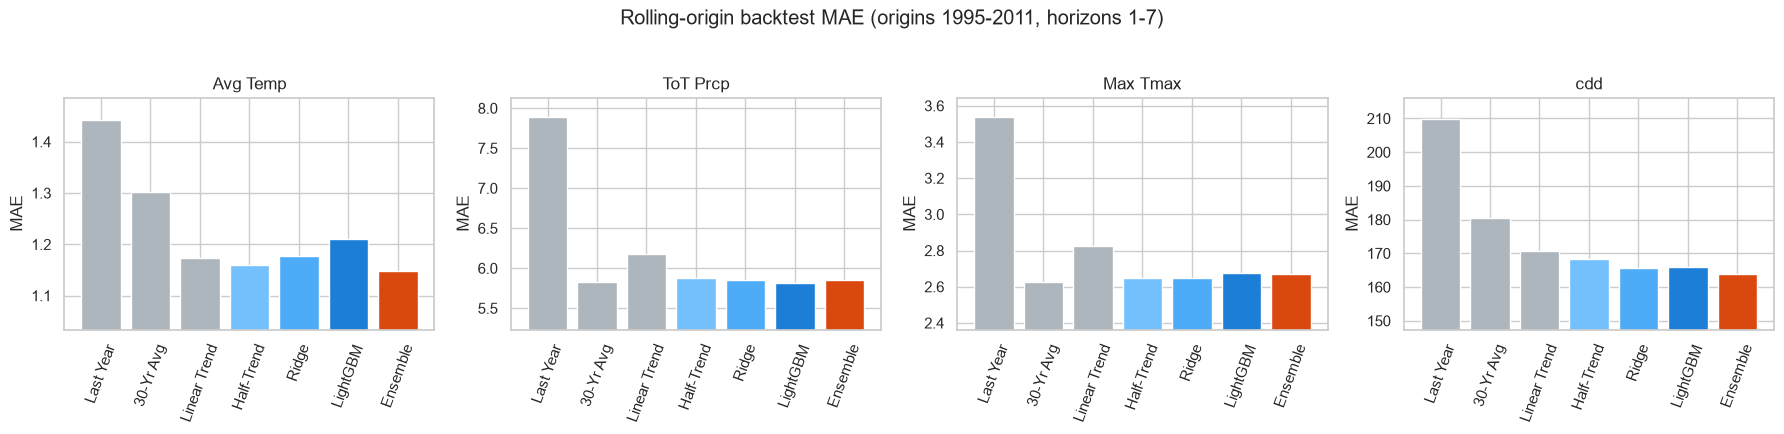

In [26]:
# Bar chart of pooled MAE
fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
colors = ['#adb5bd'] * 3 + ['#74c0fc', '#4dabf7', '#1c7ed6', '#d9480f']
for ax, c in zip(axes, TCOLS):
    ax.bar(METHODS, res.loc[c, METHODS], color=colors)
    ax.set_title(c); ax.set_ylabel('MAE'); ax.tick_params(axis='x', rotation=70)
    ax.set_ylim(res.loc[c, METHODS].min() * 0.9, res.loc[c, METHODS].max() * 1.03)
plt.suptitle('Rolling-origin backtest MAE (origins 1995-2011, horizons 1-7)', y=1.03)
plt.tight_layout(); plt.show()

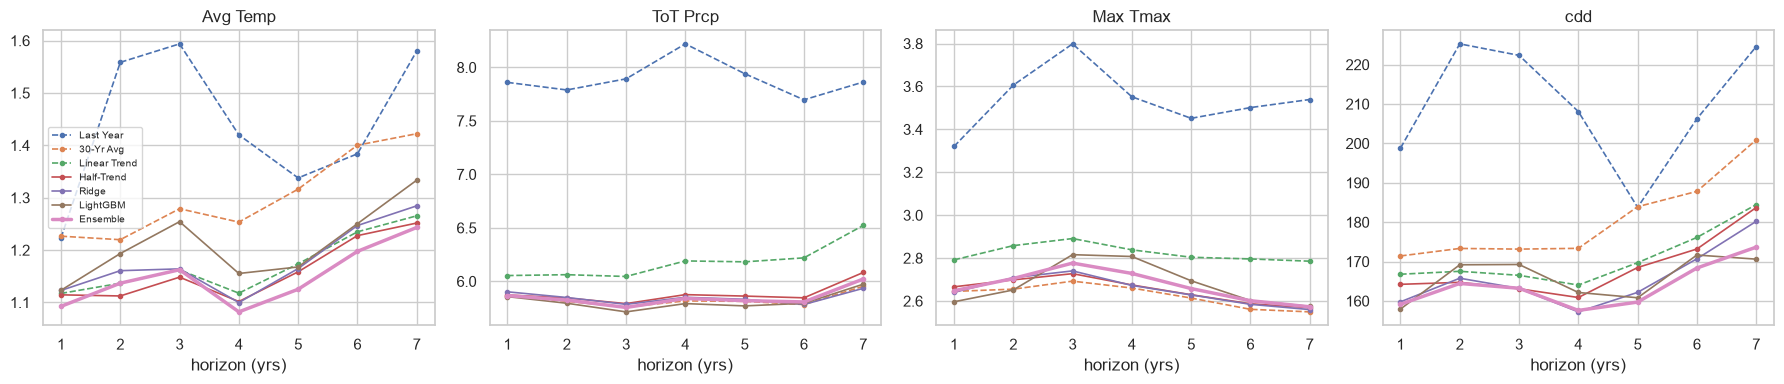

In [27]:
# MAE by horizon for all methods
bh = mae_table(bt_all, METHODS, by=['target', 'h'])
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, TCOLS):
    for m in METHODS:
        ax.plot(bh.loc[c].index, bh.loc[c, m], marker='o', ms=3, lw=2.5 if m == 'Ensemble' else 1.2,
                ls='--' if m in BASE else '-', label=m)
    ax.set_title(c); ax.set_xlabel('horizon (yrs)')
axes[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

In [28]:
# Does skill depend on the era? Split origins into early (1995-2003) and late (2004-2011)
bt_all['era'] = np.where(bt_all.origin <= 2003, '1995-2003 origins', '2004-2011 origins')
era = mae_table(bt_all, METHODS, by=['target', 'era'])
display(era.round(3))

Last Year  30-Yr Avg  Linear Trend  Half-Trend  \
target   era                                                                 
Avg Temp 1995-2003 origins      1.365      1.158         1.031       1.006   
         2004-2011 origins      1.529      1.464         1.331       1.331   
Max Tmax 1995-2003 origins      3.458      2.575         2.838       2.631   
         2004-2011 origins      3.628      2.682         2.807       2.672   
ToT Prcp 1995-2003 origins      7.661      5.668         6.078       5.766   
         2004-2011 origins      8.155      6.009         6.299       6.012   
cdd      1995-2003 origins    198.661    161.993       163.308     154.460   
         2004-2011 origins    222.403    201.371       179.070     183.872   

                              Ridge  LightGBM  Ensemble  
target   era                                             
Avg Temp 1995-2003 origins    1.030     1.094     1.004  
         2004-2011 origins    1.343     1.342     1.310  
Max Tmax 1995-2003 origins    2.594     2.593     2.630  
         2004-2011 origins    2.708     2.772     2.715  
ToT Prcp 1995-2003 origins    5.734     5.651     5.729  
         2004-2011 origins    5.975     5.995     5.981  
cdd      1995-2003 origins  154.973   154.367   153.379  
         2004-2011 origins  177.465   178.916   175.345

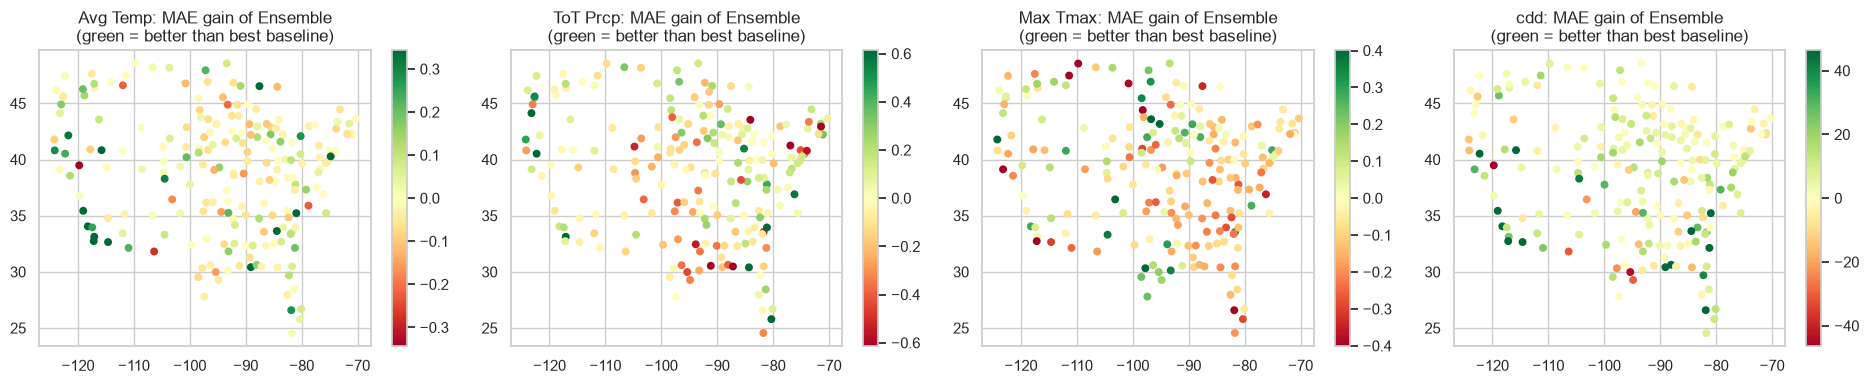

In [29]:
# Where do models help? Per-city MAE improvement of Ensemble vs best baseline, mapped.
rows = []
for c in TCOLS:
    f = bt_all[bt_all.target == c].dropna(subset=['y', 'Ensemble'] + BASE)
    ref = res.loc[c, BASE].idxmin()
    g = f.groupby('city').apply(lambda d: np.mean(np.abs(d[ref] - d['y'])) - np.mean(np.abs(d['Ensemble'] - d['y'])))
    rows.append(g.rename(c))
gain = pd.concat(rows, axis=1).join(META)
fig, axes = plt.subplots(1, 4, figsize=(19, 4))
for ax, c in zip(axes, TCOLS):
    v = gain[c].abs().quantile(0.95)
    sc = ax.scatter(gain['Lon'], gain['Lat'], c=gain[c], cmap='RdYlGn', vmin=-v, vmax=v, s=22)
    ax.set_title(f'{c}: MAE gain of Ensemble\n(green = better than best baseline)'); plt.colorbar(sc, ax=ax)
plt.tight_layout(); plt.show()

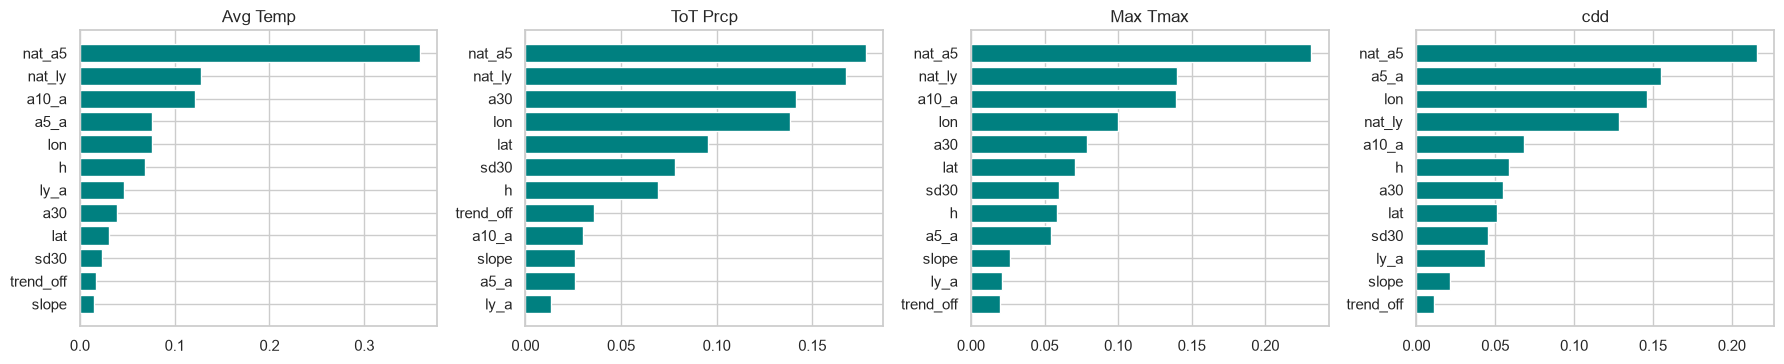

In [30]:
# Feature importance of LightGBM trained with all data through 2011 (the last backtest origin)
fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
for ax, c in zip(axes, TCOLS):
    _, g = fit_predict(c, 2011, return_models=True)
    imp = pd.Series(g.booster_.feature_importance('gain'), index=FEATS).sort_values()
    ax.barh(imp.index, imp.values / imp.sum(), color='teal'); ax.set_title(c)
plt.tight_layout(); plt.show()

## 6. Final forecast: 2019-2025 for all 210 cities

* Same pipeline as the backtest, with origin `T = 2018` and training rows limited to `origin + h <= 2018`. The submitted forecast is the

In [32]:
final = pd.concat([fit_predict(c, 2018) for c in TCOLS], ignore_index=True)
final['year'] = final['origin'] + final['h']

## Fallback for sparse stations

* **Huntsville** has valid data only for 1895-1957 and 2018 (the station record is empty 1958-2017), so no baseline or model can use a 30-year climatology directly.
* `forecast = mean(forecast of 3 nearest well-observed cities) + offset`, where `offset` is the city's average difference from those neighbors over overlapping historical years.
* This is an explicit, documented approximation. Its accuracy cannot be backtested for Huntsville itself, but it is the same logic as spatial interpolation.

In [34]:
def sparse_cities(min_valid=15):
    out = set()
    for c in TCOLS:
        m = W[c].loc[1989:2018].notna().sum()
        out |= set(m[m < min_valid].index)
    return sorted(out)

SPARSE = sparse_cities()
print('Sparse cities:', SPARSE)

def fill_sparse(final, k=3):
    final = final.copy()
    good = [c for c in CITIES if c not in SPARSE]
    for city in SPARSE:
        d = np.hypot(META.loc[good, 'Lat'] - META.loc[city, 'Lat'],
                     (META.loc[good, 'Lon'] - META.loc[city, 'Lon']) * np.cos(np.radians(META.loc[city, 'Lat'])))
        nb = d.nsmallest(k).index.tolist()
        print(f'{city}: neighbors = {nb}')
        for c in TCOLS:
            hist = W[c][city]
            offset = (hist - W[c][nb].mean(axis=1)).dropna().mean()
            for m in METHODS:
                mbf = final[(final.target == c) & final.city.isin(nb)].groupby('h')[m].mean()
                rows = (final.target == c) & (final.city == city)
                final.loc[rows, m] = final.loc[rows, 'h'].map(mbf) + offset
    return final

final = fill_sparse(final)
assert final[METHODS].notna().all().all()

best_method = res[METHODS].idxmin(axis=1)
print('Best backtest method per target:'); display(best_method.to_frame('method'))

sub = []
for c in TCOLS:
    f = final[final.target == c]
    sub.append(pd.DataFrame({'city': f['city'], 'year': f['year'], 'target': c, 'forecast': f[best_method[c]]}))
submission = pd.concat(sub).pivot_table(index=['city', 'year'], columns='target', values='forecast').reset_index()
submission = submission[['city', 'year'] + TCOLS]
print(submission.shape, '| NaNs:', int(submission[TCOLS].isna().sum().sum()))
display(submission.head(7))
submission.to_csv('forecast_2019_2025.csv', index=False)

Sparse cities: ['Huntsville']
Huntsville: neighbors = ['MuscleShoals', 'Birmingham', 'Chattanooga']
Best backtest method per target:


,method
target,
Avg Temp,Ensemble
ToT Prcp,LightGBM
Max Tmax,30-Yr Avg
cdd,Ensemble


(1470, 6) | NaNs: 0


target,city,year,Avg Temp,ToT Prcp,Max Tmax,cdd
0,Aberdeen,2019,44.046375,21.559967,98.13,650.253606
1,Aberdeen,2020,44.080120,21.524086,98.13,652.155862
2,Aberdeen,2021,44.124867,21.524086,98.13,662.077239
3,Aberdeen,2022,44.174649,21.458810,98.13,643.696763
4,Aberdeen,2023,44.205301,20.624374,98.13,647.687691
5,Aberdeen,2024,44.134108,20.871206,98.13,646.370987
6,Aberdeen,2025,44.145125,21.883933,98.13,644.844204


In [35]:
# Sanity: forecasts must be physically plausible and close to recent history
chk = submission.merge(df[df.Year == 2018][['Name'] + TCOLS].rename(columns={'Name': 'city'}), on='city', suffixes=('', '_2018'))
for c in TCOLS:
    d = (chk[c] - chk[c + '_2018']).abs()
    print(f'{c:9s} forecast range [{chk[c].min():8.1f}, {chk[c].max():8.1f}] mean |forecast - 2018| = {d.mean():6.2f}')
assert (submission['Tot Prcp'] >= 0).all() and (submission['cdd'] >= 0).all()

Avg Temp  forecast range [    38.0,     78.9] mean |forecast - 2018| =   0.63
ToT Prcp  forecast range [     2.8,     68.2] mean |forecast - 2018| =   7.81
Max Tmax  forecast range [    77.9,    119.6] mean |forecast - 2018| =   1.86
cdd       forecast range [    19.5,   5200.8] mean |forecast - 2018| = 146.48


KeyError: 'Tot Prcp'

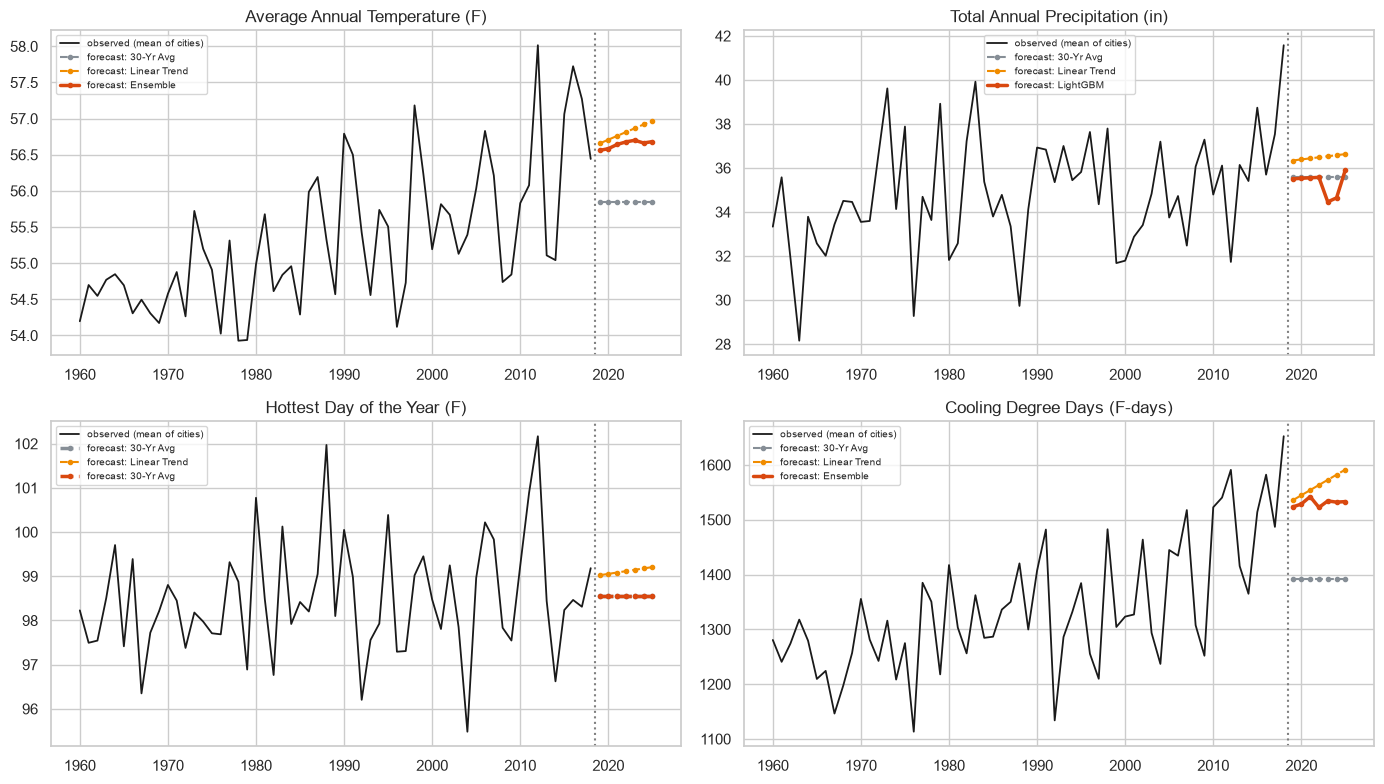

In [36]:
# National-average trajectory: history + backtested model + 2019-2025 forecast
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, (c, lab) in zip(axes.ravel(), TARGETS.items()):
    hist = df[df.Year >= 1960].groupby('Year')[c].mean()
    ax.plot(hist.index, hist.values, color='k', lw=1.3, label='observed (mean of cities)')
    for m, col in [('30-Yr Avg', '#868e96'), ('Linear Trend', '#f08c00'), (best_method[c], '#d9480f')]:
        fm = final[final.target == c].groupby('year')[m].mean()
        ax.plot(fm.index, fm.values, color=col, lw=2.5 if m == best_method[c] else 1.5, marker='o', ms=3,
                ls='--' if m in BASE else '-', label=f'forecast: {m}')
    ax.axvline(2018.5, color='gray', ls=':'); ax.set_title(lab); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

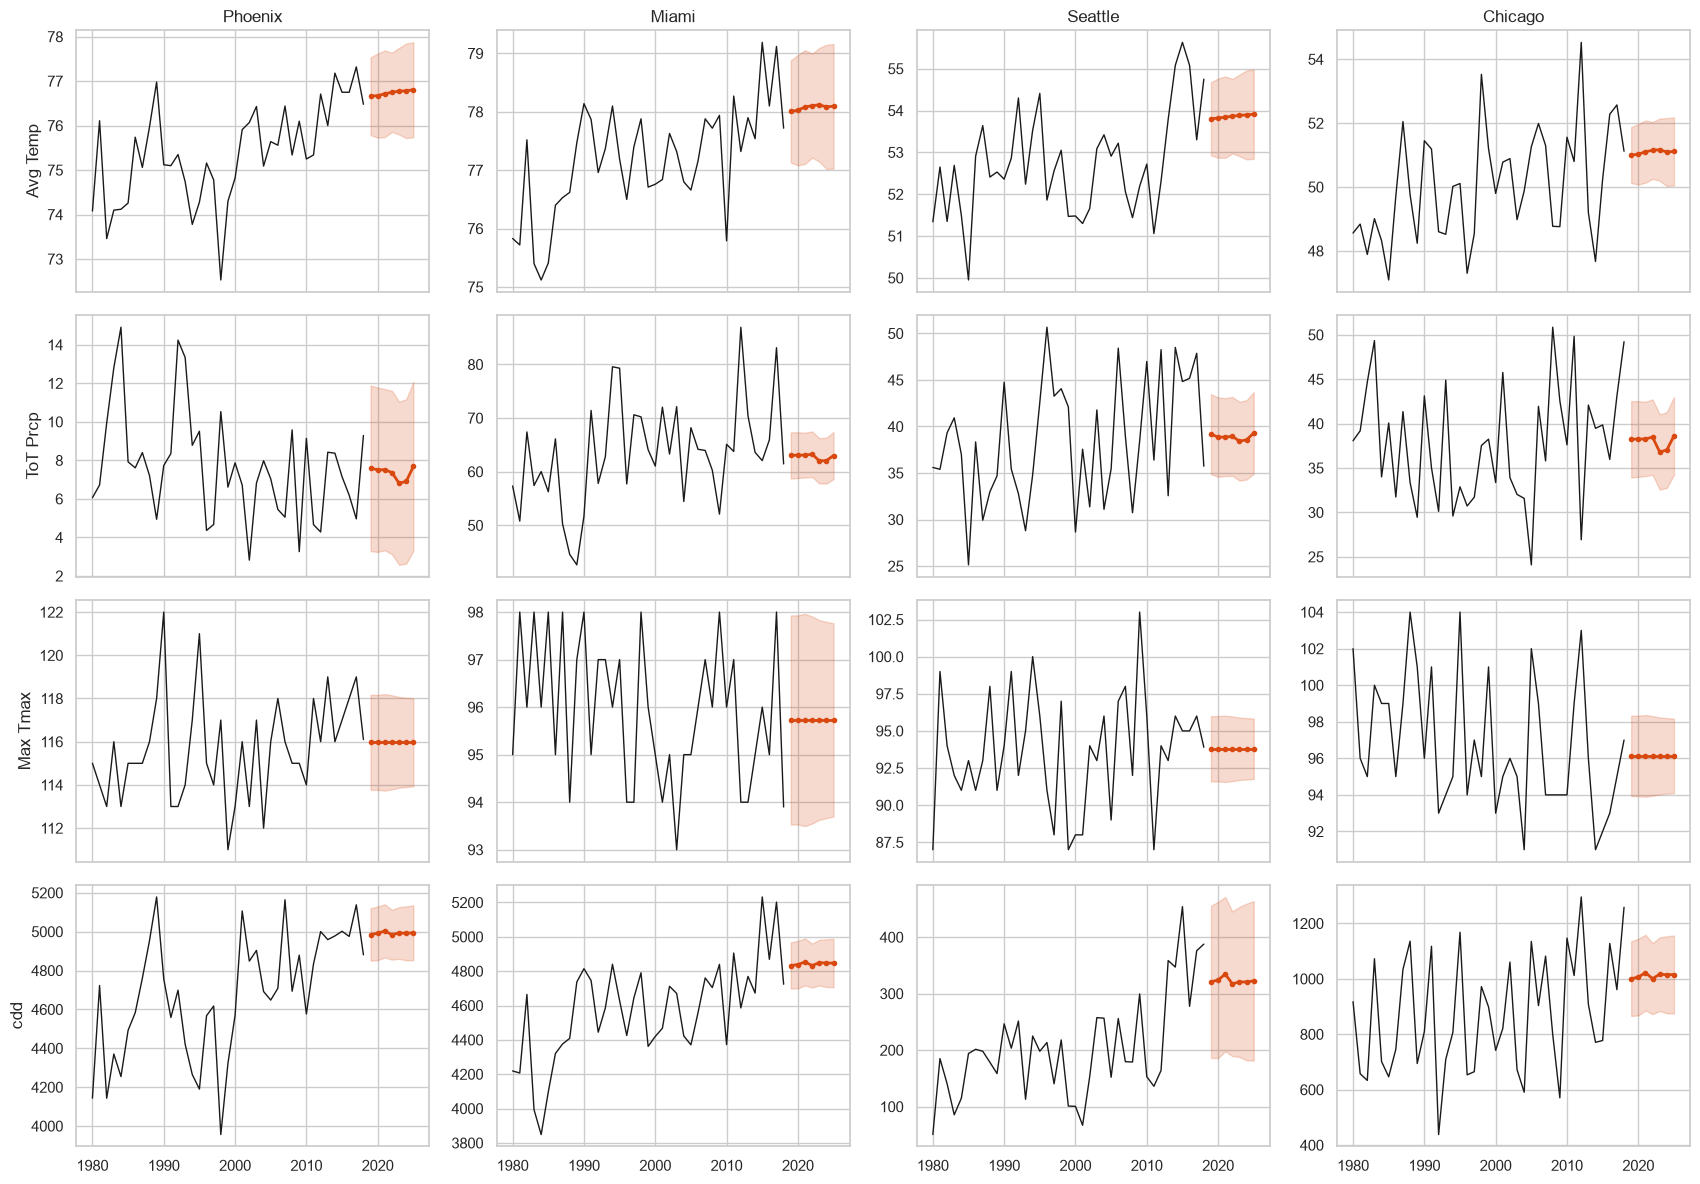

In [37]:
# Example cities: observed history and the 2019-2025 forecast with a simple empirical band
# (band = +/- the median absolute backtest error of the chosen method at that horizon)
EXAMPLES = [n for n in ['Phoenix', 'Miami', 'Seattle', 'Chicago'] if n in CITIES][:4]
fig, axes = plt.subplots(len(TCOLS), len(EXAMPLES), figsize=(4.3 * len(EXAMPLES), 3 * len(TCOLS)), sharex=True)
for i, c in enumerate(TCOLS):
    err = bt_all[bt_all.target == c].assign(e=lambda d: (d[best_method[c]] - d['y']).abs()).groupby('h')['e'].median()
    for j, city in enumerate(EXAMPLES):
        ax = axes[i, j]
        h = df[(df.Name == city) & (df.Year >= 1980)]
        ax.plot(h.Year, h[c], color='k', lw=1)
        f = final[(final.target == c) & (final.city == city)].sort_values('year')
        ax.plot(f.year, f[best_method[c]], color='#d9480f', lw=2, marker='o', ms=3)
        band = f['h'].map(err).values
        ax.fill_between(f.year, f[best_method[c]] - band, f[best_method[c]] + band, color='#d9480f', alpha=0.2)
        if i == 0: ax.set_title(city)
        if j == 0: ax.set_ylabel(c)
plt.tight_layout(); plt.show()

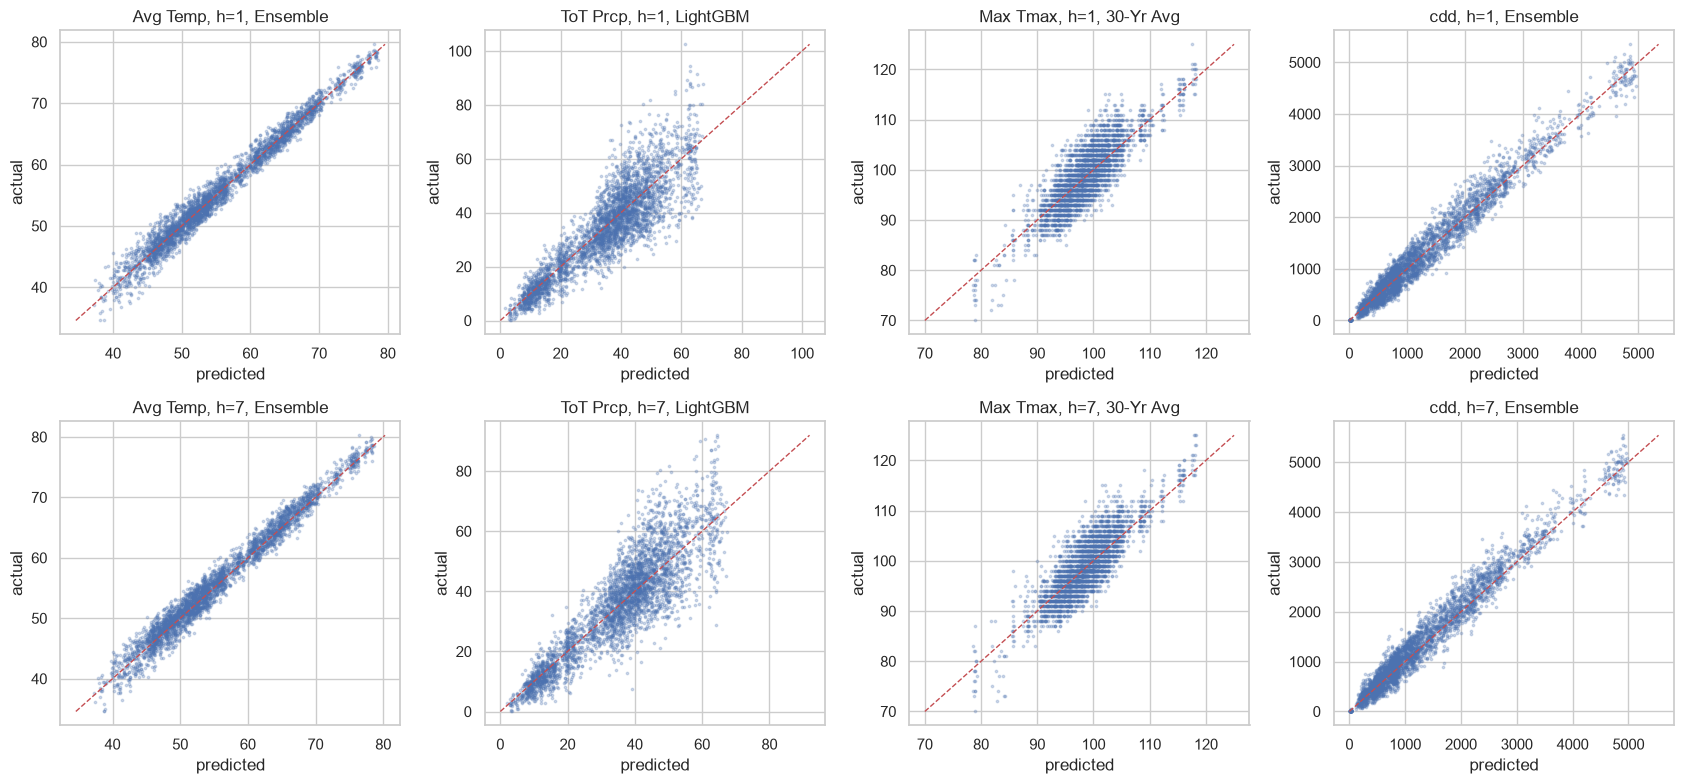

In [38]:
# Backtest calibration: observed vs predicted scatter for the chosen method, horizon 1 and 7
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for j, c in enumerate(TCOLS):
    for i, hh in enumerate([1, 7]):
        f = bt_all[(bt_all.target == c) & (bt_all.h == hh)].dropna(subset=['y', best_method[c]])
        ax = axes[i, j]
        ax.scatter(f[best_method[c]], f['y'], s=3, alpha=0.25)
        lo, hi = f['y'].min(), f['y'].max(); ax.plot([lo, hi], [lo, hi], 'r--', lw=1)
        ax.set_title(f'{c}, h={hh}, {best_method[c]}'); ax.set_xlabel('predicted'); ax.set_ylabel('actual')
plt.tight_layout(); plt.show()

## 7. What the results say (and do not say)

* **Temperature and CDD carry a real, forecastable warming signal.** Most cities warm over 1989-2018 (see 2.3), and trend-aware methods beat...
* **Precipitation and the hottest day are dominated by noise.** Lag-1 autocorrelation is near zero (2.6), cities share little common signal...
* **Last Year Repeated is the worst baseline for every metric**, because one year is mostly weather, not climate.
* The in-sample noise floor in 2.5 (mean deviation around each city's own trend) is the rough limit of what any method can reach; compare...

### Where the forecast matters most: cooling demand
Because CDD is both the most forecastable metric and the one most directly tied to energy use and heat-health risk, the policy below is based on whether predicted increase
exceeds the model's typical error (so the ranking is not driven by noise).

In [39]:
cdd_best = best_method['cdd'][cite: 9]
f_cdd = final[final.target == 'cdd'].groupby('city')[cdd_best].mean().rename('cdd_2019_25')[cite: 9]
base_cdd = W['cdd'].loc[1989:2018].mean().rename('cdd_1989_2018')[cite: 9]
pol = pd.concat([f_cdd, base_cdd, META], axis=1)[cite: 9]
pol['increase'] = pol['cdd_2019_25'] - pol['cdd_1989_2018'][cite: 9]
pol['increase_pct'] = 100 * pol['increase'] / pol['cdd_1989_2018'][cite: 9]

# Typical error of the chosen method, averaged over a 7-yr window (errors partly average out over 7 years, so this is conservative)[cite: 9]
mae_cdd = res.loc['cdd', cdd_best][cite: 9]
pol['confident'] = pol['increase'] > mae_cdd[cite: 9]
print(f'{cdd_best} CDD backtest MAE = {mae_cdd:.0f}; cities with forecast increase above that: {int(pol.confident.sum())} / {len(pol)}')[cite: 9]
display(pol.sort_values('increase', ascending=False).head(15)[['cdd_1989_2018', 'cdd_2019_25', 'increase', 'increase_pct', 'confident']].round(1))[cite: 9]

NameError: name 'cite' is not defined

NameError: name 'cite' is not defined

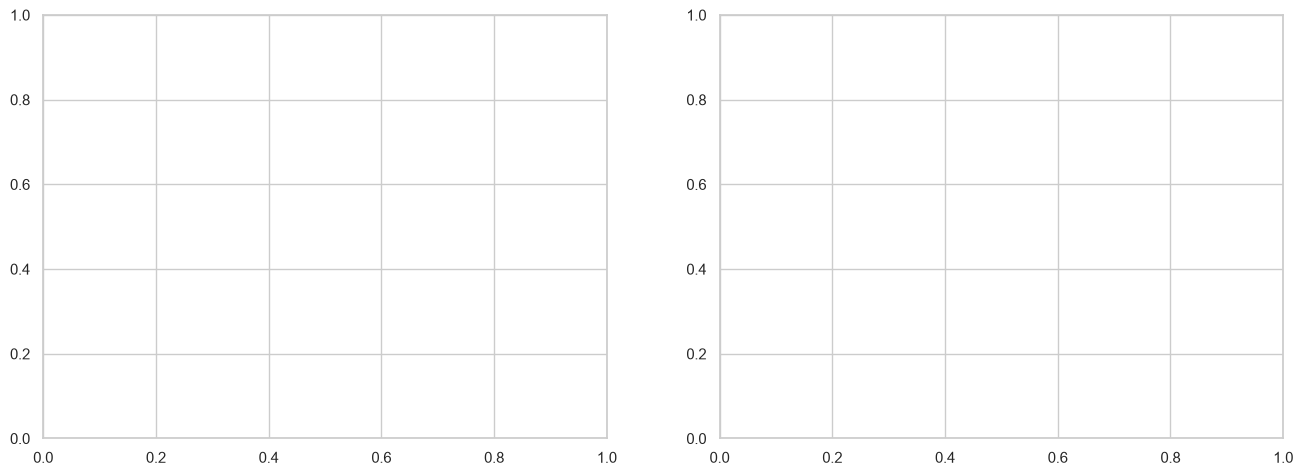

In [40]:
fig, ax = plt.subplots(1, 2, figsize=(16, 5.5))[cite: 9]
sc = ax[0].scatter(pol['Lon'], pol['Lat'], c=pol['increase'], cmap='OrRd', s=20 + 80 * pol['confident'], edgecolor='k', linewidth=0.3)[cite: 9]
plt.colorbar(sc, ax=ax[0], label='forecast CDD increase vs 1989-2018')[cite: 9]
ax[0].set_title('Expected extra cooling demand, 2019-2025 (large dots = above model error)')[cite: 9]
ax[0].set_xlabel('Lon'); ax[0].set_ylabel('Lat')[cite: 9]
top = pol.sort_values('increase', ascending=False).head(15).iloc[::-1][cite: 9]
ax[1].barh(top.index, top['increase'], color=np.where(top['confident'], '#d9480f', '#adb5bd'))[cite: 9]
ax[1].axvline(mae_cdd, color='k', ls='--', label='backtest MAE'); ax[1].legend()[cite: 9]
ax[1].set_title('15 cities with the largest forecast CDD increase')[cite: 9]
plt.tight_layout(); plt.show()[cite: 9]

## 8. Additional data recommendations

The weather record alone says *how much* cooling will be needed, not *who is hurt by it* or *whether the forecast can be improved*. Recommended sources, in priority order:

| Data | Why it helps | Use |
|---|---|---|
| **ENSO / ocean-state indices** (NOAA ONI, PDO, AMO) | Largest known driver of year-to-year US temperature and precipitation swings; known months ahead | Forecast features[cite: 10] |
| **Global mean temperature and CO2 / radiative forcing** (NASA GISTEMP, NOAA Mauna Loa) | Gives the long-term warming trend a physical anchor instead of a 30-year rolling window | Prior for city trend, physical anchor[cite: 10] |
| **Dynamical climate model outputs** (CMIP6 downscaled, e.g. LOCA2 or NEX-GDDP) | Captures regional trend differences the local record can't | Prior for city trend, long-term bounds[cite: 10] |
| **Gridded reanalyses** (ERA5, PRISM, nClimGrid) | Fills station gaps (e.g. Huntsville 1958-2017) and removes station-move artifacts | Cleaner targets, better sparse-city handling[cite: 10] |
| **Urban form** (NLCD impervious surface, tree canopy, NASA/Landsat land-surface temperature) | Urban heat island changes local heat exposure beyond airport-station readings | Spatial downscaling to city neighborhoods[cite: 10] |
| **Socioeconomic and housing** (ACS income, age 65+, A/C penetration from EIA RECS, housing age, CDC PLACES health data) | Defines who is vulnerable to a given CDD increase | Policy targeting and resource allocation[cite: 10] |
| **Energy data** (EIA monthly electricity by state/utility, utility disconnection records) | Converts CDD into actual cost burden and grid stress | Policy sizing and trigger calibration[cite: 10] |
| **Station metadata** (move history, instrument changes) | The Huntsville gap and the pre/post-1950 precision change in the early rows suggest inhomogeneities | Data QA/QC and homogenization[cite: 10] |

Data quality items found in this notebook that deserve upstream fixes: years with essentially no readings stored as `-inf` / `0.0` instead of missing; Huntsville with a 60-year gap[cite: 10].

## 9. Policy proposal: forecast-triggered cooling assistance (the "CDD Trigger")

**Problem:** Cooling demand is rising in most cities (about 94% show a positive CDD trend over 1989-2018, with a typical increase of roughly 90 CDD per decade)[cite: 10]. Building air-conditioning and grid capacity is growing fastest[cite: 10]. The hottest day of the year and rainfall are not predictable years ahead (section 7), so any policy that depends on forecasting them would be built on noise[cite: 10].

**Proposal:** Federal and state energy-assistance funds (e.g. LIHEAP's cooling component and state weatherization programs) allocate a share of money by a **forecast-triggered mechanism**:[cite: 10]

1. Each year, compute each city's 7-year CDD forecast (this pipeline) and its increase over the 30-year baseline[cite: 10].
2. Cities whose forecast increase exceeds the pipeline's published backtest error are **triggered**; this keeps the policy from reacting to noise[cite: 10].
3. Triggered cities receive multi-year funding for: (a) efficient heat-pump/AC retrofits and weatherization for low-income and older-adult households, prioritized with utility bill-protection / no-shutoff rule during heat days[cite: 10].
4. Untriggered cities keep baseline funding. The index and error bar are published so the allocation is auditable[cite: 10].

**Why this design follows from the analysis:**
* It acts on CDD, the metric where the model measurably beats the baselines, and uses the trend-aware forecast rather than last year[cite: 10].
* The trigger threshold is the measured backtest error, so false alarms from noisy years are limited by construction[cite: 10].
* It avoids promising precision on rainfall or the single hottest day, where the best method is just the climatological average[cite: 10].
* Multi-year funding matches the forecast horizon; retrofits pay back over exactly the decade-scale trend we can detect[cite: 10].

**Evaluation plan:** Track per-household cooling cost burden and heat-related ER visits in triggered vs near-threshold untriggered cities (a regression-discontinuity design)[cite: 10].

**Risks and Limits:** CDD is computed at one station per city (usually an airport), so urban heat island effects inside the city are missed; the trigger needs neighbor-smoothed adjustments[cite: 10]. Funding formulas based on a model need transparency and appeals, especially for sparse-data stations like Huntsville, which here use a neighbor-based fallback[cite: 10].

## 10. Limitations and next steps

* Backtest origins end at 2011, so the most recent warming years are only partially reflected in the evaluation. The 2004-2011 era showed larger errors for every method[cite: 10].
* Max Tmax and Tot Prcp: the best method is the 30-year average; the next gain should come from ENSO / forcing features, not from more complex models on the same data[cite: 10].
* Model hyperparameters were fixed in advance, not tuned on the backtest, to avoid overfitting the evaluation. A proper tuning pass should use nested time-based validation[cite: 10].
* Station-level metrics, not area averages. A city's true experience differs from its airport station[cite: 10].